<a href="https://colab.research.google.com/github/saracarp/buffalo_fmdv/blob/main/Copy_of_FMDV_stochastic_model_LCT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FMDV model

The model is based on the model in [Jolles et al, 2021](https://science.org/doi/10.1126/science.abd2475), simplified by (in order of decreasing complexity):

1. All waiting times are age independent. In the original, death and birth were age dependent.
2. All waiting times are exponential distributions. In the original, waning of maternal immunity, progression, and recovery from acute infection were gamma distributions.
3. The birth rate is constant in time. In the original, the birth rate is seasonal.
4. Newly infected hosts are immediately infectious. In the orignal, newly infected hosts have a short delay before becoming infectious, in the exposed class.

This version uses linear chain trick to approximate the original gamma distributions from Jolles et al. 2021, starting with carrier duration and infectious duration (recovery waiting time). According to Lloyd 2001, including gamma distributions should increase the probability of pathogen extinction.

diagram_standalone.svg

## Parameter values

These are mostly from the supplmental material to Jolles et al, 2021.

| Parameter                     |          all |          SAT1 |          SAT2 |          SAT3 |
|:------------------------------|--------------:|--------------:|--------------:|--------------:|
| Death mean waiting time       |   4.387 year  |             — |             — |             — |
| Birth mean waiting time       |   4.387 year  |             — |             — |             — |
| Waning mean waiting time      |   0.37  year  |             — |             — |             — |
| Acute transmission rate       |             — |   2.8   day⁻¹ |   1.6   day⁻¹ |   1.2   day⁻¹ |
| Carrier transmission rate     |             — |   0.028 day⁻¹ |   0.003 day⁻¹ |   0.012 day⁻¹ |
| Progression mean waiting time |             — |   0.5   day   |   1.3   day   |   2.8  day    |
| Recovery mean waiting time    |             — |   5.7  day    |   4.6  day    |   4.2  day    |
| Recovery shape parameter    |             — |   11.8      |   8.7      |   11.8      |
| Carrier probability           |             — |   0.90        |   0.44        |   0.67        |
| Carrier recovery              |             — | 243    day    | 180    day    | 174    day    |
| Carrier shape parameter              |             — |        — | 3.2        |       — |

**Note the different time units!**

We will take all of the waiting times to be exponential distributions. In Jolles et al, 2021, all except death & birth were gamma distributions, which have an extra shape parameter.

Because we will use the linear chain trick, we can only use integers for the shape parameters. We will start with carrier shape parameter, using alpha = 1 (identical to exponential), alpha = 2, alpha = 3, and alpha = 4 just for some fun comparisons of effects.

For the infectious period shape parameter, we expect this to be less important from previous sensitivity analysis. For this, we will round up to use 12 (SAT1 & SAT3) or 9 (SAT2) and determine if additional parameters are needed afterwards.

### Death

Death in Jolles et al, 2021 was age dependent, from the estimated age-dependent annual survival. Here, the mean waiting time is the mean lifetime calculated from that age-dependent annual survival.

### Birth

Birth in Jolles et al, 2021 was age dependent (menarchy at age 4 years) and seasonal, but scaled so that the expected population size is constant in time. Here, the mean waiting time is the same as for death so that the expected population size is constant in time. (In Jolles et al, 2021, the sex of hosts was also tracked and only females gave birth. Here, we will not track sex.)

### Infection

The force of infection is
$$
\lambda_\text{infection} =
\frac{\beta_\text{acute}}{N} I
+ \frac{\beta_\text{carrier}}{N} C,
$$
where $\beta$ are the transmission rates, $I$ is the number of infectious hosts, $C$ is the number of carrier hosts, and $N$ is the **initial** population size. The mean waiting time for infection is then
$$
\frac{1}{\lambda_\text{infection}}.
$$
We chose to scale the transmission rates by initial population size because we first chose the density-dependent force of infection and then wanted $R_0$ to be independent of initial population size. (The logic is a bit muddled. An alternative would be use the frequency-dependent force of infection using the same formula but with $N$ being the **current** population size.)

### Recovery

Acute infection in Jolles et al, 2021 was split between a first exposed class followed by the infectious class. The transition from exposed to infectious was called progression and the transition out of infectious was called recovery. Here, we are assuming there is no exposed class. **For our mean time to recovery, should we use their mean time to recovery or the sum of their mean times to progression and recovery?** My first instinct is to use just their mean time to recovery as it keeps $R_0$ (approximately) constant between the two models. If we use the sum, we should consider scaling the transmission rates to keep $R_0$ (approximately) constant.

**Consider comparing persistence for the two alternative mean times to recovery, with $R_0$ constant.**

# Gillespie's next-reaction method

In [1]:
import abc
import collections

import numpy
import pandas
import scipy
import joblib

import matplotlib.pyplot as plt
import seaborn

[Gillespie, 1977](https://doi.org/10.1021/j100540a008),
[Gibson & Bruck, 2000](https://doi.org/10.1021/jp993732q),
[Gillespie, 2007](https://doi.org/10.1146/annurev.physchem.58.032806.104637)

The function `simulate()` implements the algorithm in Python.

In [ ]:
def simulate(events, time_span, state_start, seed=None):
    '''Simulate with Gillespie's next-reaction method.
    `events` is a list of all the events that can occur.
    `time_span` is `(time_start, time_end)`.
    `state_start` is the state at `time_start`.
    `seed` is for the random-number generator.'''
    # Simplify by ensuring events is not empty
    assert len(events) > 0
    (time, time_end) = time_span
    # Simplify by ensuring `time_end` is finite
    assert numpy.isfinite(time_end)
    state = state_start.copy()
    # Build the random-number generator
    rng = numpy.random.default_rng(seed)
    # Initialize storage of the simulation history
    history = History()
    while True:
        history.update(time, state)
        if time >= time_end:
            break  # Exit the `while` loop
        if state['infectious'] + state['carrier_1'] + state['carrier_2'] == 0:
           break
        waiting_times = [
            event.get_waiting_time(state, rng)
            for event in events
        ]
        time_next = time + min(waiting_times)
        if time_next <= time_end:
            time = time_next
            # Find the position of the minimum in `waiting_times`
            # to find the corresponding event in `events`
            i_next = numpy.argmin(waiting_times)
            event_next = events[i_next]
            state_change = event_next.get_state_change(state, rng)
            state.update(state_change)
        else:
            # The next event is after `time_end`
            time = time_end
    return history.to_dataframe()

The exponential distribution is *memoryless*: the distribution given that the event has not yet occurred is the same as the orignal distribution. E.g., under the assumption that time to death is exponential, living buffalo with different birth dates all have the same distribution of time from now until death.

Assuming that the waiting times for all events are exponential, combined with the events being age independent, means we only need to know a buffalo's current compartment ('maternal_immunity' or 'susceptible' or ...) to accurately determine their future. Thus we can use the current count in each compartment as the `state` of the population. `collections.Counter()` is a convenient way to store those counts.

In [ ]:
state = collections.Counter({
    'maternal_immunity': 10,
    'susceptible': 50,
    'infectious': 2,
    'carrier_1': 20,
    'carrier_2': 20,
    'recovered': 100,
})
state

Counter({'maternal_immunity': 10,
         'susceptible': 50,
         'infectious': 2,
         'carrier_1': 20,
         'carrier_2': 20,
         'recovered': 100})

In [ ]:
# The state change for a waning event
state_change = collections.Counter({
    'maternal_immunity': -1,
    'susceptible': +1,
})

# Apply the change
state.update(state_change)
state

Counter({'maternal_immunity': 9,
         'susceptible': 51,
         'infectious': 2,
         'carrier_1': 20,
         'carrier_2': 20,
         'recovered': 100})

The elements of `events` must look like `Event()` below. (Ignore the `abc` things for now.)

In [ ]:
class Event(metaclass=abc.ABCMeta):
    '''Base for a kind of event.'''

    @abc.abstractmethod
    def get_waiting_time(self, state, rng):
        '''Get a random sample of the waiting time to the next event.'''
        raise NotImplementedError

    @abc.abstractmethod
    def get_state_change(self, state, rng):
        '''Get the change to `state` from this event occurring.'''
        raise NotImplementedError

For example, here is the waning event.

(Another simplification from the exponential distribution is that, if the waiting time for a single buffalo to undergo an event is exponential with mean $\mu$, the waiting time for the first of $n$ buffalo to undergo the event is exponential with mean $\mu / n$.)

In [ ]:
class Waning(Event):
    '''Waning of 'maternal_immunity' to 'susceptible'.'''

    state_change = collections.Counter({
        'maternal_immunity': -1,
        'susceptible': +1,
    })

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['waning_mean_waiting_time']

    def get_waiting_time(self, state, rng):
        count = state['maternal_immunity']
        try:
            mean = self.mean_waiting_time / count
        except ZeroDivisionError:
            return numpy.inf
        return rng.exponential(mean)

    def get_state_change(self, state, rng):
        return self.state_change

Replicating the above structure for other events: Birth, Death, Infection, and Recovery. To complete the carrier recovery with shape parameter, we will now have the same number of Carrier_Recovery events as the alpha parameter.

In [ ]:
class Birth(Event):
    '''Birth of new individuals into either 'maternal_immunity' or 'susceptible'.'''

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['birth_mean_waiting_time']

    def get_waiting_time(self, state, rng):
        count = state.total()

        try:
            mean = self.mean_waiting_time / count
        except ZeroDivisionError:
            return numpy.inf
        return rng.exponential(mean)

    def get_state_change(self, state, rng):
        n = state.total()
        p_maternal = (state['carrier_1'] + state['carrier_2'] + state['recovered']) / n
        birth = rng.choice(['maternal_immunity', 'susceptible'], 1, p=[p_maternal, 1-p_maternal])
        self.state_change = collections.Counter({
            birth[0]: +1,
        })
        return self.state_change

In [ ]:
class Death(Event):
    '''Death of an individual from any class.'''

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['death_mean_waiting_time']

    def get_waiting_time(self, state, rng):
        count = state.total()

        try:
            mean = self.mean_waiting_time / count
        except ZeroDivisionError:
            return numpy.inf
        return rng.exponential(mean)

    def get_state_change(self, state, rng):
        n = state.total()
        death = rng.choice(['maternal_immunity', 'susceptible', 'infectious', 'carrier_1', 'carrier_2', 'recovered'],
                           1,
                           p=[state['maternal_immunity']/n, state['susceptible']/n, state['infectious']/n, state['carrier_1']/n, state['carrier_2']/n, state['recovered']/n])
        self.state_change = collections.Counter({
            death[0]: -1,
        })
        return self.state_change

In [ ]:
class Infection(Event):
    '''Infection of an individual from susceptible class.'''

    state_change = collections.Counter({
        'susceptible': -1,
        'infectious': +1,
    })

    def __init__(self, parameters, state):
        self.beta_acute = parameters['acute_transmission_rate'] / state.total()
        self.beta_carrier = parameters['carrier_transmission_rate'] / state.total()

    def get_waiting_time(self, state, rng):

        count = state['susceptible']
        foi = self.beta_acute * state['infectious'] + self.beta_carrier * (state['carrier_1'] + state['carrier_2'])

        try:
            self.mean_waiting_time = 1 / foi
            mean = self.mean_waiting_time / count
        except ZeroDivisionError:
            return numpy.inf
        return rng.exponential(mean)

    def get_state_change(self, state, rng):
        return self.state_change

In [ ]:
class Recovery(Event):
    '''Infection of an individual from susceptible class.'''

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['recovery_mean_waiting_time']
        self.carrier_probability = parameters['carrier_probability']

    def get_waiting_time(self, state, rng):
        count = state['infectious']

        try:
            mean = self.mean_waiting_time / count
        except ZeroDivisionError:
            return numpy.inf
        return rng.exponential(mean)

    def get_state_change(self, state, rng):
        recovery_class = rng.choice(['carrier_1', 'recovered'],
                           1,
                           p=[self.carrier_probability, 1-self.carrier_probability])
        self.state_change = collections.Counter({
            'infectious': -1,
            recovery_class[0]: +1,
        })
        return self.state_change

In [ ]:
class Carrier_Recovery_1(Event):
    '''Infection of an individual from susceptible class.'''
    state_change = collections.Counter({
        'carrier_1': -1,
        'carrier_2': +1,
    })

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['carrier_recovery_mean_waiting_time']/2

    def get_waiting_time(self, state, rng):
        count = state['carrier_1']

        try:
            mean = self.mean_waiting_time / count
        except ZeroDivisionError:
            return numpy.inf
        return rng.exponential(mean)

    def get_state_change(self, state, rng):
       return self.state_change

In [ ]:
class Carrier_Recovery_2(Event):
    '''Infection of an individual from susceptible class.'''
    state_change = collections.Counter({
        'carrier_2': -1,
        'recovered': +1,
    })

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['carrier_recovery_mean_waiting_time']/2

    def get_waiting_time(self, state, rng):
        count = state['carrier_2']

        try:
            mean = self.mean_waiting_time / count
        except ZeroDivisionError:
            return numpy.inf
        return rng.exponential(mean)

    def get_state_change(self, state, rng):
       return self.state_change

Of less importance, here's a version of the object that stores the simulation history.

In [ ]:
class History:
    '''Record simulation history.'''

    def __init__(self):
        self.time = []
        self.state = []

    def update(self, time, state):
        '''Update for the current `time` and `state`.'''
        self.time.append(time)
        # Must `.copy()` to record current, not future, values
        state_save = collections.Counter({
            'maternal_immunity': state['maternal_immunity'],
            'suseceptible': state['susceptible'],
            'infectious': state['infectious'],
            'carrier': state['carrier_1'] + state['carrier_2'],
            'recovered': state['recovered'],
        })

        self.state.append(state_save.copy())

    def to_dataframe(self):
        '''Convert to something more useful.'''
        index = pandas.Index(self.time, name='time')
        return pandas.DataFrame(self.state, index=index)

Here's a quick example of running `simulate()`.

In [ ]:
parameters = {
    'birth_mean_waiting_time': 4.387*365.25,    # units: day
    'death_mean_waiting_time': 4.387*365.25,    # units: day
    'waning_mean_waiting_time': 0.37*365.25,    # units: day

    # Parameters for sat1
    'acute_transmission_rate': 2.8,        # units: 1/day
    'carrier_transmission_rate': 0.028,    # units: 1/day
    'progression_mean_waiting_time': 0.5,  # units: day
    'recovery_mean_waiting_time': 5.7,     # units: day
    'carrier_probability': 0.9,            # units: none
    'carrier_recovery_mean_waiting_time': 243,  # units: day
}

# `events` is a list of (instances) of kinds of `Event()`
events = (
    Waning(parameters),
    Birth(parameters),
    Death(parameters),
    Infection(parameters, state),
    Recovery(parameters),
    Carrier_Recovery_1(parameters),
    Carrier_Recovery_2(parameters)
    # etc
)

result_sat1 = simulate(events, (0, 10000), state)
result_sat1

,maternal_immunity,suseceptible,infectious,carrier,recovered
time,,,,,
0.000000,9,51,2,40,100
1.621942,8,52,2,40,100
1.708464,8,51,3,40,100
1.752020,8,51,3,40,100
2.042526,8,50,4,40,100
...,...,...,...,...,...
938.132959,15,40,0,1,136
941.168155,15,40,0,1,135
943.642039,14,41,0,1,135


The only `Event()` we have included so far is `Waning()`, so the only changes in the result are the number in 'maternal_immunity' decreasing by one and the number in 'susceptible' increasing by one at each event (plus the last entry at `time_end = 10`).

<Axes: xlabel='time'>

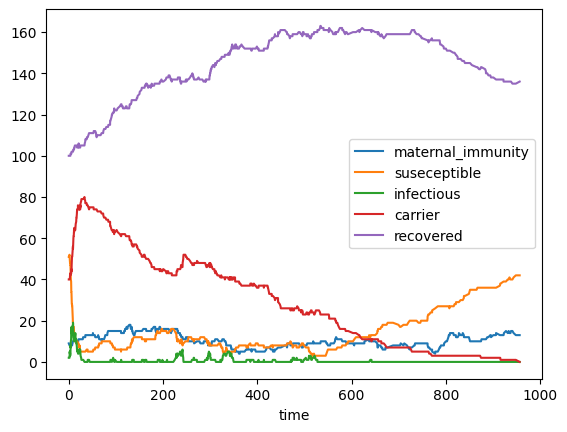

In [ ]:
result_sat1.plot()


Now we need to set realistic starting conditions--conditions that should represent the steady state of endemic circulation. To find these, we find the solution to the deterministic equations for this model: First, restate the parameters as rates (per day) and write the corresponding sets of Ordinary Differential Equations. We then hade these `odes` to `integrate.solve_ivp` to iterate and find stable dynamics, approximating the stable state. We then put these outputs into `optimize.root` to get our starting proportions, and sample from these proportions using `rng.choice` to get starting conditions.

In [ ]:
# Set the parameters for the ODEs; same as above, but all written as rates
ode_params = {
    'birth_rate': 1/(4.387*365.25),           # units: 1/day
    'death_rate': 1/(4.387*365.25),           # units: 1/day
    'waning_rate': 1/(0.37*365.25),           # units: 1/day

    'sat1_acute_transmission_rate': 2.8,      # units: 1/day
    'sat1_carrier_transmission_rate': 0.028,  # units: 1/day
    'sat1_recovery_rate': 1/5.7,              # units: 1/day
    'sat1_carrier_probability': 0.9,          # units: none
    'sat1_carrier_recovery_rate': 2/243,       # units: 1/day

    'sat2_acute_transmission_rate': 1.6,      # units: 1/day
    'sat2_carrier_transmission_rate': 0.003,  # units: 1/day
    'sat2_recovery_rate': 1/4.6,              # units: 1/day
    'sat2_carrier_probability': 0.44,          # units: none
    'sat2_carrier_recovery_rate': 2/180,       # units: 1/day

    'sat3_acute_transmission_rate': 1.2,      # units: 1/day
    'sat3_carrier_transmission_rate': 0.012,  # units: 1/day
    'sat3_recovery_rate': 1/4.2,              # units: 1/day
    'sat3_carrier_probability': 0.67,          # units: none
    'sat3_carrier_recovery_rate': 2/174,       # units: 1/day
}

In [ ]:
def odes_sat1 (t, y, parameters):
    [M, S, I, C1, C2, R] = y
    FOI = ode_params['sat1_acute_transmission_rate']*I + ode_params['sat1_carrier_transmission_rate']*(C1 + C2)
    dM = ode_params['birth_rate']*(C1 + C2 + M + R) - ode_params['waning_rate']*M - ode_params['death_rate']*M
    dS = ode_params['birth_rate']*(S + I)+ ode_params['waning_rate']*M - FOI*S  - ode_params['death_rate']*S
    dI = FOI*S - ode_params['sat1_recovery_rate']*I - ode_params['death_rate']*I
    dC1 = ode_params['sat1_recovery_rate']*ode_params['sat1_carrier_probability']*I - ode_params['sat1_carrier_recovery_rate']*C1 - ode_params['death_rate']*C1
    dC2 = ode_params['sat1_carrier_recovery_rate']*C1 - ode_params['sat1_carrier_recovery_rate']*C2 - ode_params['death_rate']*C2
    dR = ode_params['sat1_recovery_rate']*(1 - ode_params['sat1_carrier_probability'])*I + ode_params['sat1_carrier_recovery_rate']*C2 - ode_params['death_rate']*R
    return (dM, dS, dI, dC1, dC2, dR)

def odes_sat2 (t, y, parameters):
    [M, S, I, C1, C2, R] = y
    FOI = ode_params['sat2_acute_transmission_rate']*I + ode_params['sat2_carrier_transmission_rate']*(C1+C2)
    dM = ode_params['birth_rate']*(C1 + C2 + M + R) - ode_params['waning_rate']*M - ode_params['death_rate']*M
    dS = ode_params['birth_rate']*(S + I)+ ode_params['waning_rate']*M - FOI*S  - ode_params['death_rate']*S
    dI = FOI*S - ode_params['sat2_recovery_rate']*I - ode_params['death_rate']*I
    dC1 = ode_params['sat2_recovery_rate']*ode_params['sat2_carrier_probability']*I - ode_params['sat2_carrier_recovery_rate']*C1 - ode_params['death_rate']*C1
    dC2 = ode_params['sat2_carrier_recovery_rate']*C1 - ode_params['sat2_carrier_recovery_rate']*C2 - ode_params['death_rate']*C2
    dR = ode_params['sat2_recovery_rate']*(1 - ode_params['sat2_carrier_probability'])*I + ode_params['sat2_carrier_recovery_rate']*C2 - ode_params['death_rate']*R
    return (dM, dS, dI, dC1, dC2, dR)

def odes_sat3 (t, y, parameters):
    [M, S, I, C1, C2, R] = y
    FOI = ode_params['sat3_acute_transmission_rate']*I + ode_params['sat3_carrier_transmission_rate']*(C1+C2)
    dM = ode_params['birth_rate']*(C1 + C2 + M + R) - ode_params['waning_rate']*M - ode_params['death_rate']*M
    dS = ode_params['birth_rate']*(S + I)+ ode_params['waning_rate']*M - FOI*S  - ode_params['death_rate']*S
    dI = FOI*S - ode_params['sat3_recovery_rate']*I - ode_params['death_rate']*I
    dC1 = ode_params['sat3_recovery_rate']*ode_params['sat3_carrier_probability']*I - ode_params['sat3_carrier_recovery_rate']*C1 - ode_params['death_rate']*C1
    dC2 = ode_params['sat3_carrier_recovery_rate']*C1 - ode_params['sat3_carrier_recovery_rate']*C2 - ode_params['death_rate']*C2
    dR = ode_params['sat3_recovery_rate']*(1 - ode_params['sat3_carrier_probability'])*I + ode_params['sat3_carrier_recovery_rate']*C2 - ode_params['death_rate']*R
    return (dM, dS, dI, dC1, dC2, dR)

In [ ]:
def odes_sat1_wrap (y, t, parameters):
  return odes_sat1(t, y, parameters)

def odes_sat2_wrap (y, t, parameters):
  return odes_sat2(t, y, parameters)

def odes_sat3_wrap (y, t, parameters):
  return odes_sat3(t, y, parameters)

Solve for SAT1: `p_sat1` are the starting proportions for each group (Maternal, Susceptible, Infectious, Carrier, Recovered)

In [ ]:
solution_sat1 = scipy.integrate.solve_ivp(odes_sat1, [0,10000], [0.2,0.2,0.2,0.1,0.1,0.2], args = (ode_params,))
assert solution_sat1.success
sol_sat1 = solution_sat1.y[0:6,-1]

In [ ]:
opt_sat1 = scipy.optimize.root(odes_sat1_wrap, sol_sat1, args = (0, ode_params,))
assert opt_sat1.success
assert opt_sat1.x.all() > 0
p_sat1 = opt_sat1.x /opt_sat1.x.sum()
p_sat1

array([0.07389994, 0.04676957, 0.00311693, 0.05558132, 0.05166385,
       0.76896839])

Solve for SAT2: `p_sat2` are the starting proportions for each group (Maternal, Susceptible, Infectious, Carrier, Recovered)

In [ ]:
solution_sat2 = scipy.integrate.solve_ivp(odes_sat2, [0,10000], [0.2,0.2,0.2,0.1,0.1,0.2], args = (ode_params,))
assert solution_sat2.success

sol_sat2 = solution_sat2.y[0:6,-1]
sol_sat2

array([0.06731177, 0.13237426, 0.00228182, 0.01864248, 0.01768751,
       0.76170215])

In [ ]:
opt_sat2 = scipy.optimize.root(odes_sat2_wrap, sol_sat2, args = (0, ode_params,))
assert opt_sat2.success
assert opt_sat2.x.all() > 0
p_sat2 = opt_sat2.x /opt_sat2.x.sum()
p_sat2 # Something very very wrong here--returning a solution with essentially only susceptibles

array([0.06729035, 0.13257392, 0.00229044, 0.01866909, 0.01767626,
       0.76149994])

Solve for SAT3: `p_sat3` are the starting proportions for each group (Maternal, Susceptible, Infectious, Carrier, Recovered)

In [ ]:
solution_sat3 = scipy.integrate.solve_ivp(odes_sat3, [0,10000], [0.2,0.2,0.2,0.1,0.1,0.2], args = (ode_params,))
assert solution_sat3.success

sol_sat3 = solution_sat3.y[0:6,-1]
sol_sat3

array([0.06530789, 0.15832563, 0.00203015, 0.02671536, 0.0253433 ,
       0.72227767])

In [ ]:
opt_sat3 = scipy.optimize.root(odes_sat3_wrap, sol_sat3, args = (0, ode_params,))
assert opt_sat3.success
assert opt_sat3.x.all() > 0
p_sat3 = opt_sat3.x /opt_sat3.x.sum()
p_sat3 # Something very very wrong here--returning a solution with essentially only susceptibles

array([0.0653091 , 0.15830706, 0.0020297 , 0.02671859, 0.02534261,
       0.72229294])

Checking to make sure the random sampling to build starting population works. We will start with a herd of 1000 buffaloes for each and condition this that there must be at least 2 infectious individuals at the start; if less than 2 infected individuals in the starting pop, we resample until this condition is met. Slightly different strategy that used for `Jolles et al. 2021` but I think a similar result...

In [ ]:
start_sat1 = sol_sat1 / sol_sat1.sum()
rng = numpy.random.default_rng()
while True:
  start_class = rng.choice(['maternal_immunity','susceptible','infectious','carrier_1','carrier_2','recovered'],
                           1000,
                           p=p_sat1)
  start = collections.Counter(start_class)
  if  start['infectious']>= 2:
            break

start

Counter({np.str_('recovered'): 776,
         np.str_('susceptible'): 37,
         np.str_('carrier_1'): 60,
         np.str_('maternal_immunity'): 70,
         np.str_('carrier_2'): 52,
         np.str_('infectious'): 5})

Looks like it works! Re-simulate for each SAT below, using starting conditions for that SAT. Note the die-out of SAT2 quickly under these conditions....

<Axes: xlabel='time'>

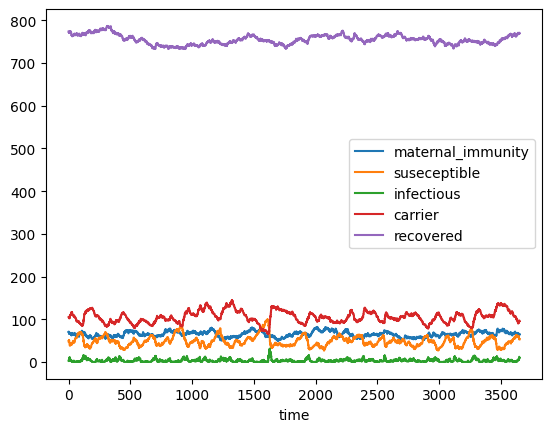

In [ ]:
# SAT1

parameters = {
    'birth_mean_waiting_time': 4.387*365.25,    # units: day
    'death_mean_waiting_time': 4.387*365.25,    # units: day
    'waning_mean_waiting_time': 0.37*365.25,    # units: day

    # Parameters for sat1
    'acute_transmission_rate': 2.8,        # units: 1/day
    'carrier_transmission_rate': 0.028,    # units: 1/day
    'progression_mean_waiting_time': 0.5,  # units: day
    'recovery_mean_waiting_time': 5.7,     # units: day
    'carrier_probability': 0.9,            # units: none
    'carrier_recovery_mean_waiting_time': 243,  # units: day
}

rng = numpy.random.default_rng()
while True:
  start_state = rng.choice(['maternal_immunity','susceptible','infectious','carrier_1','carrier_2', 'recovered'],
                           1000,
                           p=p_sat1)
  state = collections.Counter(start_state)
  if  state['infectious']>= 2:
            break

# `events` is a list of (instances) of kinds of `Event()`
events = (
    Waning(parameters),
    Birth(parameters),
    Death(parameters),
    Infection(parameters, state),
    Recovery(parameters),
    Carrier_Recovery_1(parameters),
    Carrier_Recovery_2(parameters),
    # etc
)

result_sat1 = simulate(events, (0, 365*10), state, rng)
result_sat1.plot()

<Axes: xlabel='time'>

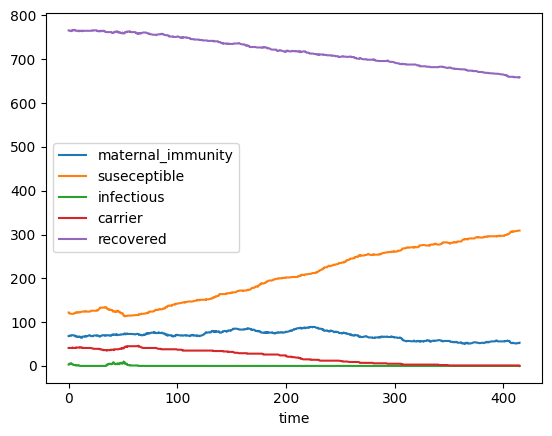

In [ ]:
# SAT2

parameters = {
    'birth_mean_waiting_time': 4.387*365.25,    # units: day
    'death_mean_waiting_time': 4.387*365.25,    # units: day
    'waning_mean_waiting_time': 0.37*365.25,    # units: day

    # Parameters for sat2
    'acute_transmission_rate': 1.6,        # units: 1/day
    'carrier_transmission_rate': 0.003,    # units: 1/day
    'recovery_mean_waiting_time': 4.6,     # units: day
    'carrier_probability': 0.44,            # units: none
    'carrier_recovery_mean_waiting_time': 180,  # units: day
}

rng = numpy.random.default_rng()
while True:
  start_state = rng.choice(['maternal_immunity','susceptible','infectious','carrier_1','carrier_2','recovered'],
                           1000,
                           p=p_sat2)
  state = collections.Counter(start_state)
  if  state['infectious']>= 2:
            break

# `events` is a list of (instances) of kinds of `Event()`
events = (
    Waning(parameters),
    Birth(parameters),
    Death(parameters),
    Infection(parameters, state),
    Recovery(parameters),
    Carrier_Recovery_1(parameters),
    Carrier_Recovery_2(parameters),
    # etc
)

result_sat2 = simulate(events, (0, 365*10), state)
result_sat2.plot()

<Axes: xlabel='time'>

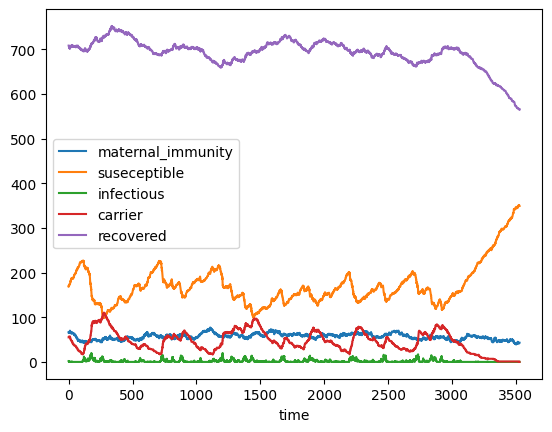

In [ ]:
# SAT3

parameters = {
    'birth_mean_waiting_time': 4.387*365.25,    # units: day
    'death_mean_waiting_time': 4.387*365.25,    # units: day
    'waning_mean_waiting_time': 0.37*365.25,    # units: day

    # Parameters for sat3
    'acute_transmission_rate': 1.2,        # units: 1/day
    'carrier_transmission_rate': 0.012,    # units: 1/day
    'recovery_mean_waiting_time': 4.2,     # units: day
    'carrier_probability': 0.67,            # units: none
    'carrier_recovery_mean_waiting_time': 174,  # units: day
}

rng = numpy.random.default_rng()
while True:
  start_state = rng.choice(['maternal_immunity','susceptible','infectious','carrier_1','carrier_2','recovered'],
                           1000,
                           p=p_sat3)
  state = collections.Counter(start_state)
  if  state['infectious']>= 2:
            break

# `events` is a list of (instances) of kinds of `Event()`
events = (
    Waning(parameters),
    Birth(parameters),
    Death(parameters),
    Infection(parameters, state),
    Recovery(parameters),
    Carrier_Recovery_1(parameters),
    Carrier_Recovery_2(parameters),
    # etc
)

result_sat3 = simulate(events, (0, 365*10), state)
result_sat3.plot()

Now we will set up to run parallel simuations using joblib. First we set up a function to wrap simulation, starting each simulation with a seeded random number generator, sampled starting population from proportions, and finally iterating across time with the simulate function.

In [ ]:
def run_one(seed = None):
  rng = numpy.random.default_rng(seed)


  while True:
      start_state = rng.choice(['maternal_immunity','susceptible','infectious','carrier_1','carrier_2','recovered'],
                              1000,
                              p=p_start)
      state = collections.Counter(start_state)
      if  state['infectious']>= 2:
        break

  # `events` is a list of (instances) of kinds of `Event()`
  events = (
      Waning(parameters),
      Birth(parameters),
      Death(parameters),
      Infection(parameters, state),
      Recovery(parameters),
      Carrier_Recovery_1(parameters),
      Carrier_Recovery_2(parameters),
      # etc
  )

  result = simulate(events, (0, 365*10), state, rng)
  #result = result[['maternal_immunity','susceptible','infectious','carrier','recovered']]
  return result

Now that that our function to run one simulation is completed, we generate 100 random numbers and use these to iterate SAT1 simulations. Note that we don't really need to pass parameters and state and p_sat1 to run_one, but this just helps keep everything on track.

In [ ]:
parameters = {
  'birth_mean_waiting_time': 4.387*365.25,    # units: day
  'death_mean_waiting_time': 4.387*365.25,    # units: day
  'waning_mean_waiting_time': 0.37*365.25,    # units: day
   # Parameters for sat1
  'acute_transmission_rate': 2.8,        # units: 1/day
  'carrier_transmission_rate': 0.028,    # units: 1/day
  'progression_mean_waiting_time': 0.5,  # units: day
  'recovery_mean_waiting_time': 5.7,     # units: day
  'carrier_probability': 0.9,            # units: none
  'carrier_recovery_mean_waiting_time': 243,  # units: day
}

# set starting pouplation proportions for sat1--from solve.root above
#p_start = [0.07407783, 0.04447496, 0.00312443, 0.10409354, 0.77422924]
p_start = [0.07389994, 0.04676957, 0.00311693, 0.05558132, 0.05166385, 0.76896839]

rng = numpy.random.default_rng(seed = 87)
rngs = rng.spawn(1000)

reps_sat1 = joblib.Parallel(n_jobs=-1, verbose = 2)(joblib.delayed(run_one)(rng) for rng in rngs)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed:   20.5s
[Parallel(n_jobs=-1)]: Done 158 tasks      | elapsed:  1.4min
[Parallel(n_jobs=-1)]: Done 361 tasks      | elapsed:  3.2min
[Parallel(n_jobs=-1)]: Done 644 tasks      | elapsed:  5.6min
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:  8.6min finished


In [ ]:
reps_sat1[0:5]

[             maternal_immunity  suseceptible  infectious  carrier  recovered
 time                                                                        
 0.000000                    70            55           3      103        769
 0.137517                    71            55           3      103        769
 0.459882                    71            54           4      103        769
 0.498248                    70            55           4      103        769
 0.509544                    70            55           4      102        770
 ...                        ...           ...         ...      ...        ...
 3648.610247                 65            40           3      129        728
 3649.445065                 65            40           3      128        729
 3649.711829                 65            40           2      129        729
 3649.898788                 65            40           1      130        729
 3650.000000                 65            40           1      1

In [ ]:
reps_sat1[0]

,maternal_immunity,suseceptible,infectious,carrier,recovered
time,,,,,
0.000000,70,55,3,103,769
0.137517,71,55,3,103,769
0.459882,71,54,4,103,769
0.498248,70,55,4,103,769
0.509544,70,55,4,102,770
...,...,...,...,...,...
3648.610247,65,40,3,129,728
3649.445065,65,40,3,128,729
3649.711829,65,40,2,129,729


In [ ]:
reps_sat1[-1]


sat1_extinct = []

for i in range(0,1000):
    extinction_year = reps_sat1[i].index[-1]
    final_infected = reps_sat1[i].values[-1,2] + reps_sat1[i].values[-1,3]

    if final_infected == 0:
        extinction = True
    else: extinction = False


    new_row = {'extinction': extinction, 'extinction_year': extinction_year, 'final_infected': final_infected}
    sat1_extinct.append(new_row)

sat1_extinct = pandas.DataFrame(sat1_extinct)
sat1_extinct

,extinction,extinction_year,final_infected
0,False,3650.0,131
1,False,3650.0,116
2,False,3650.0,128
3,False,3650.0,83
4,False,3650.0,90
...,...,...,...
995,False,3650.0,94
996,False,3650.0,74
997,False,3650.0,95
998,False,3650.0,86


In [ ]:
parameters = {
    'birth_mean_waiting_time': 4.387*365.25,    # units: day
    'death_mean_waiting_time': 4.387*365.25,    # units: day
    'waning_mean_waiting_time': 0.37*365.25,    # units: day

    # Parameters for sat2
    'acute_transmission_rate': 1.6,        # units: 1/day
    'carrier_transmission_rate': 0.003,    # units: 1/day
    'recovery_mean_waiting_time': 4.6,     # units: day
    'carrier_probability': 0.44,            # units: none
    'carrier_recovery_mean_waiting_time': 180,  # units: day
}


# set starting pouplation proportions for sat2--from solve.root above
#p_start = [0.06726549, 0.13289442, 0.00228959, 0.03543969, 0.76211081]
p_start = [0.06731177, 0.13237426, 0.00228182, 0.01864248, 0.01768751, 0.76170215]

rng = numpy.random.default_rng(seed = 87)
rngs = rng.spawn(1000)

reps_sat2 = joblib.Parallel(n_jobs=-1, verbose = 2)(joblib.delayed(run_one)(rng) for rng in rngs)

reps_sat2[0:5]

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed:    4.0s
[Parallel(n_jobs=-1)]: Done 158 tasks      | elapsed:   16.1s
[Parallel(n_jobs=-1)]: Done 361 tasks      | elapsed:   37.5s
[Parallel(n_jobs=-1)]: Done 644 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:  1.7min finished


[             maternal_immunity  suseceptible  infectious  carrier  recovered
 time                                                                        
 0.000000                    71           147           2       28        752
 0.215407                    71           147           2       28        751
 0.391112                    70           148           2       28        751
 0.453796                    70           148           1       29        751
 0.476026                    70           147           2       29        751
 ...                        ...           ...         ...      ...        ...
 1199.023147                 41           333           0        1        606
 1200.577326                 40           334           0        1        606
 1201.216553                 40           333           0        1        606
 1201.298088                 39           334           0        1        606
 1201.681724                 39           334           0       

In [ ]:
sat2_extinct = []

for i in range(0,1000):
    extinction_year = reps_sat2[i].index[-1]
    final_infected = reps_sat2[i].values[-1,2] + reps_sat2[i].values[-1,3]

    if final_infected == 0:
        extinction = True
    else: extinction = False


    new_row = {'extinction': extinction, 'extinction_year': extinction_year, 'final_infected': final_infected}
    sat2_extinct.append(new_row)

sat2_extinct = pandas.DataFrame(sat2_extinct)
sat2_extinct

,extinction,extinction_year,final_infected
0,True,1201.681724,0
1,True,560.343091,0
2,True,868.937994,0
3,True,804.636664,0
4,True,444.937621,0
...,...,...,...
995,True,1074.222193,0
996,True,505.032595,0
997,True,926.656650,0
998,True,438.267887,0


In [ ]:
parameters = {
    'birth_mean_waiting_time': 4.387*365.25,    # units: day
    'death_mean_waiting_time': 4.387*365.25,    # units: day
    'waning_mean_waiting_time': 0.37*365.25,    # units: day

    # Parameters for sat3
    'acute_transmission_rate': 1.2,        # units: 1/day
    'carrier_transmission_rate': 0.012,    # units: 1/day
    'recovery_mean_waiting_time': 4.2,     # units: day
    'carrier_probability': 0.67,            # units: none
    'carrier_recovery_mean_waiting_time': 174,  # units: day
}

# set starting pouplation proportions for sat3--from solve.root above
#p_start = [0.06524898, 0.1590819 , 0.00202783, 0.05077322, 0.72286807]
p_start = [0.0653091 , 0.15830706, 0.0020297 , 0.02671859, 0.02534261, 0.72229294]

rng = numpy.random.default_rng(seed = 87)
rngs = rng.spawn(1000)

reps_sat3 = joblib.Parallel(n_jobs=-1, verbose = 2)(joblib.delayed(run_one)(rng) for rng in rngs)

reps_sat3[0:3]

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed:   15.7s
[Parallel(n_jobs=-1)]: Done 158 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done 361 tasks      | elapsed:  2.7min
[Parallel(n_jobs=-1)]: Done 644 tasks      | elapsed:  4.8min
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:  7.4min finished


[             maternal_immunity  suseceptible  infectious  carrier  recovered
 time                                                                        
 0.000000                    70           151           5       47        727
 0.387680                    70           151           4       47        728
 0.420247                    70           151           4       47        727
 0.568838                    70           151           4       47        726
 0.812720                    71           151           4       47        726
 ...                        ...           ...         ...      ...        ...
 3649.053547                 67           190           0       24        799
 3649.448226                 67           190           0       23        799
 3649.651605                 67           190           0       23        798
 3649.922387                 67           189           0       23        798
 3650.000000                 67           189           0       

In [ ]:
sat3_extinct = []

for i in range(0,1000):
    extinction_year = reps_sat3[i].index[-1]
    final_infected = reps_sat3[i].values[-1,2] + reps_sat3[i].values[-1,3]

    if final_infected == 0:
        extinction = True
    else: extinction = False

    new_row = {'extinction': extinction, 'extinction_year': extinction_year, 'final_infected': final_infected}
    sat3_extinct.append(new_row)

sat3_extinct = pandas.DataFrame(sat3_extinct)
sat3_extinct

,extinction,extinction_year,final_infected
0,False,3650.000000,23
1,False,3650.000000,93
2,False,3650.000000,91
3,True,788.198704,0
4,False,3650.000000,56
...,...,...,...
995,False,3650.000000,36
996,False,3650.000000,25
997,False,3650.000000,99
998,True,3158.919790,0


First, pull out the basic summaries: the number of simulations that went extinct during the 10-year simulation and the average year to extiction (given extinction occurred).

In [ ]:
sat1_extinct['extinction'].value_counts()

,count
extinction,
False,1000


In [ ]:
sat2_extinct['extinction'].value_counts()

,count
extinction,
True,994
False,6


In [ ]:
sat2_extinct.query("extinction == True")['extinction_year'].mean()

np.float64(935.2005659614416)

In [ ]:
sat2_extinct.query("extinction == True")['extinction_year'].median()

737.8598492307749

In [ ]:
sat2_extinct.query("extinction == True")['extinction_year']

,extinction_year
0,1201.681724
1,560.343091
2,868.937994
3,804.636664
4,444.937621
...,...
995,1074.222193
996,505.032595
997,926.656650
998,438.267887


In [ ]:
sat3_extinct['extinction'].value_counts()

,count
extinction,
False,843
True,157


In [ ]:
sat3_extinct.query("extinction == True")['extinction_year'].mean()

np.float64(2093.003040156792)

In [ ]:
sat3_extinct.query("extinction == True")['extinction_year'].median()

2201.7573295196153

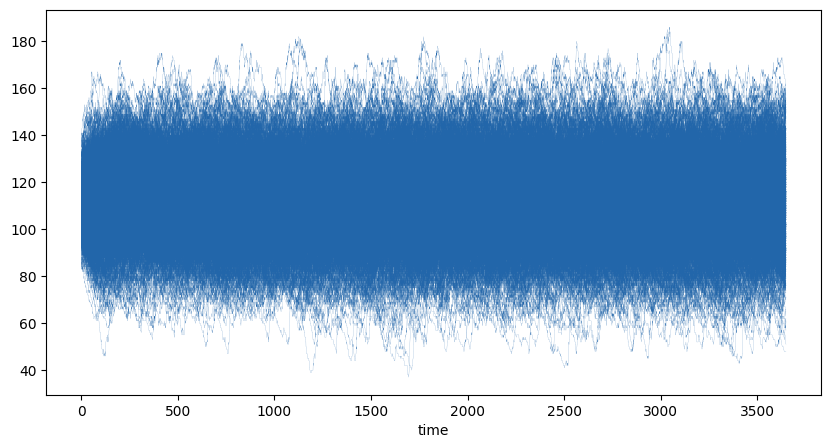

In [ ]:

fig, ax = plt.subplots(figsize=(10, 5))

for i in range(0,1000):
    reps_sat1[i]['total_infected'] = reps_sat1[i]['infectious'] + reps_sat1[i]['carrier']
    reps_sat1[i]['total_infected'].plot(ax=ax, color = '#2266aa', alpha = 1, lw = 0.1)


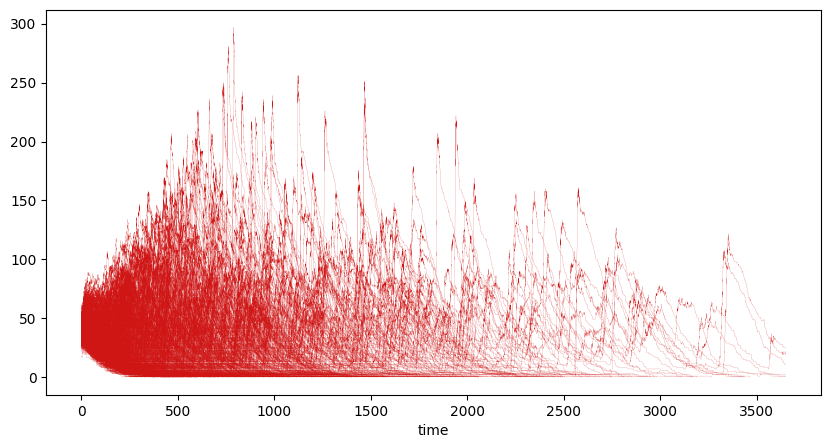

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

for i in range(0,1000):
    reps_sat2[i]['total_infected'] = reps_sat2[i]['infectious'] + reps_sat2[i]['carrier']
    reps_sat2[i]['total_infected'].plot(ax=ax, color = '#d01515', alpha = 1, lw = 0.1)

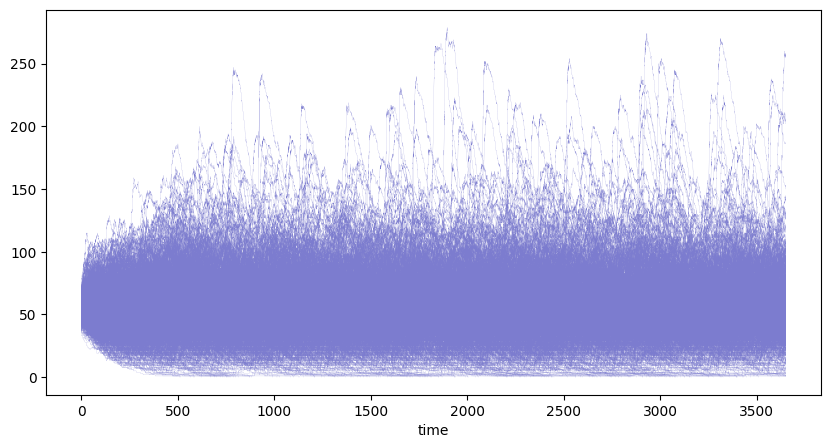

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

for i in range(0,1000):
    reps_sat3[i]['total_infected'] = reps_sat3[i]['infectious'] + reps_sat3[i]['carrier']
    reps_sat3[i]['total_infected'].plot(ax=ax, color = '#7c7ccf', alpha = 1, lw = 0.1)

# Increase shape parameter for carrier class

Repeat above with alpha = 3 for carrier duration

In [2]:
def simulate(events, time_span, state_start, seed=None):
    '''Simulate with Gillespie's next-reaction method.
    `events` is a list of all the events that can occur.
    `time_span` is `(time_start, time_end)`.
    `state_start` is the state at `time_start`.
    `seed` is for the random-number generator.'''
    # Simplify by ensuring events is not empty
    assert len(events) > 0
    (time, time_end) = time_span
    # Simplify by ensuring `time_end` is finite
    assert numpy.isfinite(time_end)
    state = state_start.copy()
    # Build the random-number generator
    rng = numpy.random.default_rng(seed)
    # Initialize storage of the simulation history
    history = History()
    while True:
        history.update(time, state)
        if time >= time_end:
            break  # Exit the `while` loop
        if state['infectious'] + state['carrier_1'] + state['carrier_2'] + state['carrier_3']== 0:
           break
        waiting_times = [
            event.get_waiting_time(state, rng)
            for event in events
        ]
        time_next = time + min(waiting_times)
        if time_next <= time_end:
            time = time_next
            # Find the position of the minimum in `waiting_times`
            # to find the corresponding event in `events`
            i_next = numpy.argmin(waiting_times)
            event_next = events[i_next]
            state_change = event_next.get_state_change(state, rng)
            state.update(state_change)
        else:
            # The next event is after `time_end`
            time = time_end
    return history.to_dataframe()

Going ahead and redefining all of the events...

In [3]:
class Event(metaclass=abc.ABCMeta):
    '''Base for a kind of event.'''

    @abc.abstractmethod
    def get_waiting_time(self, state, rng):
        '''Get a random sample of the waiting time to the next event.'''
        raise NotImplementedError

    @abc.abstractmethod
    def get_state_change(self, state, rng):
        '''Get the change to `state` from this event occurring.'''
        raise NotImplementedError

In [4]:
class Waning(Event):
    '''Waning of 'maternal_immunity' to 'susceptible'.'''

    state_change = collections.Counter({
        'maternal_immunity': -1,
        'susceptible': +1,
    })

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['waning_mean_waiting_time']

    def get_waiting_time(self, state, rng):
        count = state['maternal_immunity']
        try:
            mean = self.mean_waiting_time / count
        except ZeroDivisionError:
            return numpy.inf
        return rng.exponential(mean)

    def get_state_change(self, state, rng):
        return self.state_change

In [5]:
class Birth(Event):
    '''Birth of new individuals into either 'maternal_immunity' or 'susceptible'.'''

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['birth_mean_waiting_time']

    def get_waiting_time(self, state, rng):
        count = state.total()

        try:
            mean = self.mean_waiting_time / count
        except ZeroDivisionError:
            return numpy.inf
        return rng.exponential(mean)

    def get_state_change(self, state, rng):
        n = state.total()
        p_maternal = (state['carrier_1'] + state['carrier_2'] + state['carrier_3'] + state['recovered']) / n
        birth = rng.choice(['maternal_immunity', 'susceptible'], 1, p=[p_maternal, 1-p_maternal])
        self.state_change = collections.Counter({
            birth[0]: +1,
        })
        return self.state_change

In [6]:
class Death(Event):
    '''Death of an individual from any class.'''

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['death_mean_waiting_time']

    def get_waiting_time(self, state, rng):
        count = state.total()

        try:
            mean = self.mean_waiting_time / count
        except ZeroDivisionError:
            return numpy.inf
        return rng.exponential(mean)

    def get_state_change(self, state, rng):
        n = state.total()
        death = rng.choice(['maternal_immunity', 'susceptible', 'infectious', 'carrier_1', 'carrier_2', 'carrier_3', 'recovered'],
                           1,
                           p=[state['maternal_immunity']/n, state['susceptible']/n, state['infectious']/n, state['carrier_1']/n, state['carrier_2']/n, state['carrier_3']/n, state['recovered']/n])
        self.state_change = collections.Counter({
            death[0]: -1,
        })
        return self.state_change

In [7]:
class Infection(Event):
    '''Infection of an individual from susceptible class.'''

    state_change = collections.Counter({
        'susceptible': -1,
        'infectious': +1,
    })

    def __init__(self, parameters, state):
        self.beta_acute = parameters['acute_transmission_rate'] / state.total()
        self.beta_carrier = parameters['carrier_transmission_rate'] / state.total()

    def get_waiting_time(self, state, rng):

        count = state['susceptible']
        foi = self.beta_acute * state['infectious'] + self.beta_carrier * (state['carrier_1'] + state['carrier_2'] + state['carrier_3'])

        try:
            self.mean_waiting_time = 1 / foi
            mean = self.mean_waiting_time / count
        except ZeroDivisionError:
            return numpy.inf
        return rng.exponential(mean)

    def get_state_change(self, state, rng):
        return self.state_change

In [8]:
class Recovery(Event):
    '''Infection of an individual from susceptible class.'''

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['recovery_mean_waiting_time']
        self.carrier_probability = parameters['carrier_probability']

    def get_waiting_time(self, state, rng):
        count = state['infectious']

        try:
            mean = self.mean_waiting_time / count
        except ZeroDivisionError:
            return numpy.inf
        return rng.exponential(mean)

    def get_state_change(self, state, rng):
        recovery_class = rng.choice(['carrier_1', 'recovered'],
                           1,
                           p=[self.carrier_probability, 1-self.carrier_probability])
        self.state_change = collections.Counter({
            'infectious': -1,
            recovery_class[0]: +1,
        })
        return self.state_change

In [9]:
class Carrier_Recovery_1(Event):
    '''Infection of an individual from susceptible class.'''
    state_change = collections.Counter({
        'carrier_1': -1,
        'carrier_2': +1,
    })

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['carrier_recovery_mean_waiting_time']/3

    def get_waiting_time(self, state, rng):
        count = state['carrier_1']

        try:
            mean = self.mean_waiting_time / count
        except ZeroDivisionError:
            return numpy.inf
        return rng.exponential(mean)

    def get_state_change(self, state, rng):
       return self.state_change

In [10]:
class Carrier_Recovery_2(Event):
    '''Infection of an individual from susceptible class.'''
    state_change = collections.Counter({
        'carrier_2': -1,
        'carrier_3': +1,
    })

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['carrier_recovery_mean_waiting_time']/3

    def get_waiting_time(self, state, rng):
        count = state['carrier_2']

        try:
            mean = self.mean_waiting_time / count
        except ZeroDivisionError:
            return numpy.inf
        return rng.exponential(mean)

    def get_state_change(self, state, rng):
       return self.state_change

In [11]:
class Carrier_Recovery_3(Event):
    '''Infection of an individual from susceptible class.'''
    state_change = collections.Counter({
        'carrier_3': -1,
        'recovered': +1,
    })

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['carrier_recovery_mean_waiting_time']/3

    def get_waiting_time(self, state, rng):
        count = state['carrier_3']

        try:
            mean = self.mean_waiting_time / count
        except ZeroDivisionError:
            return numpy.inf
        return rng.exponential(mean)

    def get_state_change(self, state, rng):
       return self.state_change

In [12]:
class History:
    '''Record simulation history.'''

    def __init__(self):
        self.time = []
        self.state = []

    def update(self, time, state):
        '''Update for the current `time` and `state`.'''
        self.time.append(time)
        # Must `.copy()` to record current, not future, values
        state_save = collections.Counter({
            'maternal_immunity': state['maternal_immunity'],
            'suseceptible': state['susceptible'],
            'infectious': state['infectious'],
            'carrier': state['carrier_1'] + state['carrier_2'] + state['carrier_3'],
            'recovered': state['recovered'],
        })

        self.state.append(state_save.copy())

    def to_dataframe(self):
        '''Convert to something more useful.'''
        index = pandas.Index(self.time, name='time')
        return pandas.DataFrame(self.state, index=index)

In [13]:
# Set the parameters for the ODEs; same as above, but all written as rates
ode_params = {
    'birth_rate': 1/(4.387*365.25),           # units: 1/day
    'death_rate': 1/(4.387*365.25),           # units: 1/day
    'waning_rate': 1/(0.37*365.25),           # units: 1/day

    'sat1_acute_transmission_rate': 2.8,      # units: 1/day
    'sat1_carrier_transmission_rate': 0.028,  # units: 1/day
    'sat1_recovery_rate': 1/5.7,              # units: 1/day
    'sat1_carrier_probability': 0.9,          # units: none
    'sat1_carrier_recovery_rate': 3/243,       # units: 1/day

    'sat2_acute_transmission_rate': 1.6,      # units: 1/day
    'sat2_carrier_transmission_rate': 0.003,  # units: 1/day
    'sat2_recovery_rate': 1/4.6,              # units: 1/day
    'sat2_carrier_probability': 0.44,          # units: none
    'sat2_carrier_recovery_rate': 3/180,       # units: 1/day

    'sat3_acute_transmission_rate': 1.2,      # units: 1/day
    'sat3_carrier_transmission_rate': 0.012,  # units: 1/day
    'sat3_recovery_rate': 1/4.2,              # units: 1/day
    'sat3_carrier_probability': 0.67,          # units: none
    'sat3_carrier_recovery_rate': 3/174,       # units: 1/day
}

In [14]:
def odes_sat1 (t, y, parameters):
    [M, S, I, C1, C2, C3, R] = y
    FOI = ode_params['sat1_acute_transmission_rate']*I + ode_params['sat1_carrier_transmission_rate']*(C1 + C2 +C3)
    dM = ode_params['birth_rate']*(C1 + C2 + C3 + M + R) - ode_params['waning_rate']*M - ode_params['death_rate']*M
    dS = ode_params['birth_rate']*(S + I)+ ode_params['waning_rate']*M - FOI*S  - ode_params['death_rate']*S
    dI = FOI*S - ode_params['sat1_recovery_rate']*I - ode_params['death_rate']*I
    dC1 = ode_params['sat1_recovery_rate']*ode_params['sat1_carrier_probability']*I - ode_params['sat1_carrier_recovery_rate']*C1 - ode_params['death_rate']*C1
    dC2 = ode_params['sat1_carrier_recovery_rate']*C1 - ode_params['sat1_carrier_recovery_rate']*C2 - ode_params['death_rate']*C2
    dC3 = ode_params['sat1_carrier_recovery_rate']*C2 - ode_params['sat1_carrier_recovery_rate']*C3 - ode_params['death_rate']*C3
    dR = ode_params['sat1_recovery_rate']*(1 - ode_params['sat1_carrier_probability'])*I + ode_params['sat1_carrier_recovery_rate']*C3 - ode_params['death_rate']*R
    return (dM, dS, dI, dC1, dC2, dC3, dR)

def odes_sat2 (t, y, parameters):
    [M, S, I, C1, C2, C3, R] = y
    FOI = ode_params['sat2_acute_transmission_rate']*I + ode_params['sat2_carrier_transmission_rate']*(C1+C2+C3)
    dM = ode_params['birth_rate']*(C1 + C2 + C3 + M + R) - ode_params['waning_rate']*M - ode_params['death_rate']*M
    dS = ode_params['birth_rate']*(S + I)+ ode_params['waning_rate']*M - FOI*S  - ode_params['death_rate']*S
    dI = FOI*S - ode_params['sat2_recovery_rate']*I - ode_params['death_rate']*I
    dC1 = ode_params['sat2_recovery_rate']*ode_params['sat2_carrier_probability']*I - ode_params['sat2_carrier_recovery_rate']*C1 - ode_params['death_rate']*C1
    dC2 = ode_params['sat2_carrier_recovery_rate']*C1 - ode_params['sat2_carrier_recovery_rate']*C2 - ode_params['death_rate']*C2
    dC3 = ode_params['sat2_carrier_recovery_rate']*C2 - ode_params['sat2_carrier_recovery_rate']*C3 - ode_params['death_rate']*C3
    dR = ode_params['sat2_recovery_rate']*(1 - ode_params['sat2_carrier_probability'])*I + ode_params['sat2_carrier_recovery_rate']*C3 - ode_params['death_rate']*R
    return (dM, dS, dI, dC1, dC2, dC3, dR)

def odes_sat3 (t, y, parameters):
    [M, S, I, C1, C2, C3, R] = y
    FOI = ode_params['sat3_acute_transmission_rate']*I + ode_params['sat3_carrier_transmission_rate']*(C1+C2+C3)
    dM = ode_params['birth_rate']*(C1 + C2 + C3 + M + R) - ode_params['waning_rate']*M - ode_params['death_rate']*M
    dS = ode_params['birth_rate']*(S + I)+ ode_params['waning_rate']*M - FOI*S  - ode_params['death_rate']*S
    dI = FOI*S - ode_params['sat3_recovery_rate']*I - ode_params['death_rate']*I
    dC1 = ode_params['sat3_recovery_rate']*ode_params['sat3_carrier_probability']*I - ode_params['sat3_carrier_recovery_rate']*C1 - ode_params['death_rate']*C1
    dC2 = ode_params['sat3_carrier_recovery_rate']*C1 - ode_params['sat3_carrier_recovery_rate']*C2 - ode_params['death_rate']*C2
    dC3 = ode_params['sat3_carrier_recovery_rate']*C2 - ode_params['sat3_carrier_recovery_rate']*C3 - ode_params['death_rate']*C3
    dR = ode_params['sat3_recovery_rate']*(1 - ode_params['sat3_carrier_probability'])*I + ode_params['sat3_carrier_recovery_rate']*C3 - ode_params['death_rate']*R
    return (dM, dS, dI, dC1, dC2, dC3, dR)

In [15]:
def odes_sat1_wrap (y, t, parameters):
  return odes_sat1(t, y, parameters)

def odes_sat2_wrap (y, t, parameters):
  return odes_sat2(t, y, parameters)

def odes_sat3_wrap (y, t, parameters):
  return odes_sat3(t, y, parameters)

In [16]:
solution_sat1 = scipy.integrate.solve_ivp(odes_sat1, [0,10000], [0.2,0.2,0.1,0.1,0.1,0.1,0.2], args = (ode_params,))
assert solution_sat1.success
sol_sat1 = solution_sat1.y[:,-1]

opt_sat1 = scipy.optimize.root(odes_sat1_wrap, sol_sat1, args = (0, ode_params,))
assert opt_sat1.success
assert opt_sat1.x.all() > 0
p_sat1 = opt_sat1.x /opt_sat1.x.sum()
p_sat1

array([0.07390788, 0.04666711, 0.00311726, 0.03794978, 0.03612371,
       0.03438549, 0.76784877])

In [17]:
solution_sat2 = scipy.integrate.solve_ivp(odes_sat2, [0,10000], [0.2,0.2,0.1,0.1,0.1,0.1,0.2], args = (ode_params,))
assert solution_sat2.success

sol_sat2 = solution_sat2.y[:,-1]

opt_sat2 = scipy.optimize.root(odes_sat2_wrap, sol_sat2, args = (0, ode_params,))
assert opt_sat2.success
assert opt_sat2.x.all() > 0
p_sat2 = opt_sat2.x /opt_sat2.x.sum()
p_sat2

array([0.0673196 , 0.1321968 , 0.00229143, 0.01267618, 0.01221865,
       0.01177764, 0.76151968])

In [18]:
solution_sat3 = scipy.integrate.solve_ivp(odes_sat3, [0,10000], [0.2,0.2,0.1,0.1,0.1,0.1,0.2], args = (ode_params,))
assert solution_sat3.success

sol_sat3 = solution_sat3.y[:,-1]

opt_sat3 = scipy.optimize.root(odes_sat3_wrap, sol_sat3, args = (0, ode_params,))
assert opt_sat3.success
assert opt_sat3.x.all() > 0
p_sat3 = opt_sat3.x /opt_sat3.x.sum()
p_sat3

array([0.06532848, 0.1580573 , 0.0020303 , 0.01812889, 0.0174956 ,
       0.01688444, 0.72207499])

In [19]:
def run_one(seed = None):
  rng = numpy.random.default_rng(seed)


  while True:
      start_state = rng.choice(['maternal_immunity','susceptible','infectious','carrier_1','carrier_2','carrier_3','recovered'],
                              1000,
                              p=p_start)
      state = collections.Counter(start_state)
      if  state['infectious']>= 2:
        break

  # `events` is a list of (instances) of kinds of `Event()`
  events = (
      Waning(parameters),
      Birth(parameters),
      Death(parameters),
      Infection(parameters, state),
      Recovery(parameters),
      Carrier_Recovery_1(parameters),
      Carrier_Recovery_2(parameters),
      Carrier_Recovery_3(parameters),
      # etc
  )

  result = simulate(events, (0, 365*10), state, rng)
  #result = result[['maternal_immunity','susceptible','infectious','carrier','recovered']]
  return result

In [20]:
parameters = {
  'birth_mean_waiting_time': 4.387*365.25,    # units: day
  'death_mean_waiting_time': 4.387*365.25,    # units: day
  'waning_mean_waiting_time': 0.37*365.25,    # units: day
   # Parameters for sat1
  'acute_transmission_rate': 2.8,        # units: 1/day
  'carrier_transmission_rate': 0.028,    # units: 1/day
  'progression_mean_waiting_time': 0.5,  # units: day
  'recovery_mean_waiting_time': 5.7,     # units: day
  'carrier_probability': 0.9,            # units: none
  'carrier_recovery_mean_waiting_time': 243,  # units: day
}

# set starting pouplation proportions for sat1--from solve.root above
p_start = [0.07390788, 0.04666711, 0.00311726, 0.03794978, 0.03612371, 0.03438549, 0.76784877]

rng = numpy.random.default_rng(seed = 87)
rngs = rng.spawn(1000)

reps_sat1 = joblib.Parallel(n_jobs=-1, verbose = 2)(joblib.delayed(run_one)(rng) for rng in rngs)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed:   35.6s
[Parallel(n_jobs=-1)]: Done 158 tasks      | elapsed:  2.2min
[Parallel(n_jobs=-1)]: Done 361 tasks      | elapsed:  4.7min
[Parallel(n_jobs=-1)]: Done 644 tasks      | elapsed:  8.2min
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed: 12.8min finished


In [21]:
reps_sat1[-1]


sat1_extinct = []

for i in range(0,1000):
    extinction_year = reps_sat1[i].index[-1]
    final_infected = reps_sat1[i].values[-1,2] + reps_sat1[i].values[-1,3]

    if final_infected == 0:
        extinction = True
    else: extinction = False


    new_row = {'extinction': extinction, 'extinction_year': extinction_year, 'final_infected': final_infected}
    sat1_extinct.append(new_row)

sat1_extinct = pandas.DataFrame(sat1_extinct)

In [22]:
sat1_extinct['extinction'].value_counts()

,count
extinction,
False,1000


<Axes: xlabel='day'>

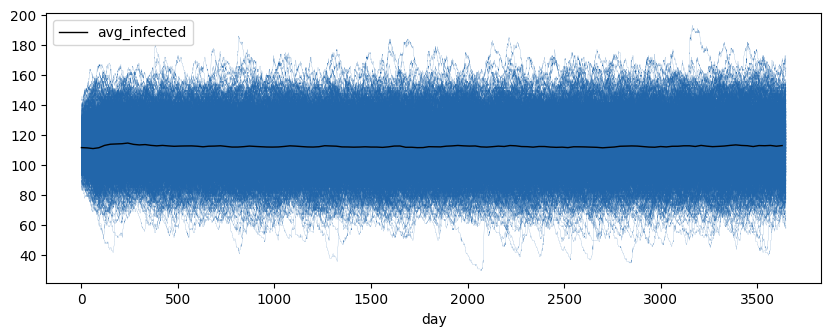

In [23]:
sat1_mean_inf = []
n_day = []

for d in range(0,3650,30):
  n_day = []
  for i in range(0,1000):
    n = reps_sat1[i].asof(d)['infectious'] + reps_sat1[i].asof(d)['carrier']

    if n > 0:
        n_day.append(n)

  n_avg = sum(n_day)/len(n_day)
  day_mean = {'day': d, 'avg_infected': n_avg}
  sat1_mean_inf.append(day_mean)

sat1_mean_inf = pandas.DataFrame(sat1_mean_inf)

fig, ax = plt.subplots(figsize=(10, 3.5))

for i in range(0,1000):
    reps_sat1[i]['total_infected'] = reps_sat1[i]['infectious'] + reps_sat1[i]['carrier']
    reps_sat1[i]['total_infected'].plot(ax=ax, color = '#2266aa', alpha = 1, lw = 0.1)

sat1_mean_inf.plot(ax=ax, x = 'day', y = 'avg_infected', color = 'black', lw = 1)

In [26]:
parameters = {
    'birth_mean_waiting_time': 4.387*365.25,    # units: day
    'death_mean_waiting_time': 4.387*365.25,    # units: day
    'waning_mean_waiting_time': 0.37*365.25,    # units: day

    # Parameters for sat2
    'acute_transmission_rate': 1.6,        # units: 1/day
    'carrier_transmission_rate': 0.003,    # units: 1/day
    'recovery_mean_waiting_time': 4.6,     # units: day
    'carrier_probability': 0.44,            # units: none
    'carrier_recovery_mean_waiting_time': 180,  # units: day
}


# set starting pouplation proportions for sat2--from solve.root above
p_start = [0.0673196 , 0.1321968 , 0.00229143, 0.01267618, 0.01221865, 0.01177764, 0.76151970]

rng = numpy.random.default_rng(seed = 87)
rngs = rng.spawn(1000)

reps_sat2 = joblib.Parallel(n_jobs=-1, verbose = 2)(joblib.delayed(run_one)(rng) for rng in rngs)


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed:    5.6s
[Parallel(n_jobs=-1)]: Done 158 tasks      | elapsed:   19.1s
[Parallel(n_jobs=-1)]: Done 361 tasks      | elapsed:   39.9s
[Parallel(n_jobs=-1)]: Done 644 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:  1.8min finished


In [27]:
sat2_extinct = []

for i in range(0,1000):
    extinction_year = reps_sat2[i].index[-1]
    final_infected = reps_sat2[i].values[-1,2] + reps_sat2[i].values[-1,3]

    if final_infected == 0:
        extinction = True
    else: extinction = False


    new_row = {'extinction': extinction, 'extinction_year': extinction_year, 'final_infected': final_infected}
    sat2_extinct.append(new_row)

sat2_extinct = pandas.DataFrame(sat2_extinct)

In [28]:
sat2_extinct['extinction'].value_counts()

,count
extinction,
True,1000


In [29]:
sat2_extinct.query("extinction == True")['extinction_year'].mean()

np.float64(687.0351378435007)

In [30]:
sat2_extinct.query("extinction == True")['extinction_year'].median()

558.361765135523

<Axes: xlabel='day'>

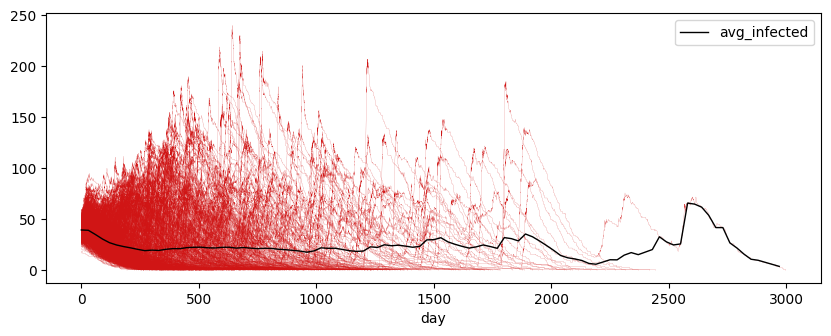

In [32]:
sat2_mean_inf = []
n_day = []

for d in range(0,3650,30):
  n_day = []
  for i in range(0,1000):
    n = reps_sat2[i].asof(d)['infectious'] + reps_sat2[i].asof(d)['carrier']

    if n > 0:
        n_day.append(n)

  if len(n_day) > 0:
    n_avg = sum(n_day)/len(n_day)
    day_mean = {'day': d, 'avg_infected': n_avg}
    sat2_mean_inf.append(day_mean)
  else:
    break

sat2_mean_inf = pandas.DataFrame(sat2_mean_inf)

fig, ax = plt.subplots(figsize=(10, 3.5))

for i in range(0,1000):
    reps_sat2[i]['total_infected'] = reps_sat2[i]['infectious'] + reps_sat2[i]['carrier']
    reps_sat2[i]['total_infected'].plot(ax=ax, color = '#d01515', alpha = 1, lw = 0.1)

sat2_mean_inf.plot(ax=ax, x = 'day', y = 'avg_infected', color = 'black', lw = 1)

<Axes: xlabel='extinction_year', ylabel='Density'>

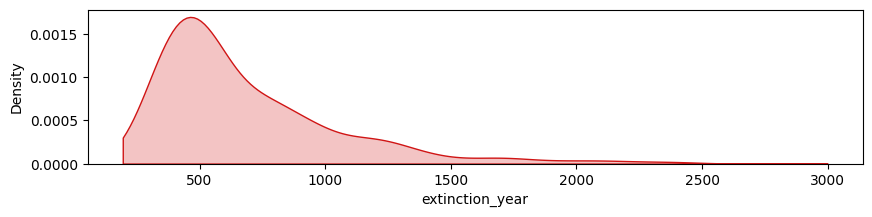

In [33]:
sat2_extinct_true = sat2_extinct.query("extinction == True")

fig, ax = plt.subplots(figsize=(10, 2))

seaborn.kdeplot(data=sat2_extinct_true, x="extinction_year",
                cut = 0, color = '#d01515', fill = True)

In [34]:
parameters = {
    'birth_mean_waiting_time': 4.387*365.25,    # units: day
    'death_mean_waiting_time': 4.387*365.25,    # units: day
    'waning_mean_waiting_time': 0.37*365.25,    # units: day

    # Parameters for sat3
    'acute_transmission_rate': 1.2,        # units: 1/day
    'carrier_transmission_rate': 0.012,    # units: 1/day
    'recovery_mean_waiting_time': 4.2,     # units: day
    'carrier_probability': 0.67,            # units: none
    'carrier_recovery_mean_waiting_time': 174,  # units: day
}

# set starting pouplation proportions for sat3--from solve.root above
#p_start = [0.06524898, 0.1590819 , 0.00202783, 0.05077322, 0.72286807]
p_start = [0.06532848, 0.1580573 , 0.0020303 , 0.01812889, 0.0174956 , 0.01688444, 0.72207499]

rng = numpy.random.default_rng(seed = 87)
rngs = rng.spawn(1000)

reps_sat3 = joblib.Parallel(n_jobs=-1, verbose = 2)(joblib.delayed(run_one)(rng) for rng in rngs)


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed:   25.7s
[Parallel(n_jobs=-1)]: Done 158 tasks      | elapsed:  1.6min
[Parallel(n_jobs=-1)]: Done 361 tasks      | elapsed:  3.6min
[Parallel(n_jobs=-1)]: Done 644 tasks      | elapsed:  6.4min
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:  9.9min finished


In [35]:
sat3_extinct = []

for i in range(0,1000):
    extinction_year = reps_sat3[i].index[-1]
    final_infected = reps_sat3[i].values[-1,2] + reps_sat3[i].values[-1,3]

    if final_infected == 0:
        extinction = True
    else: extinction = False

    new_row = {'extinction': extinction, 'extinction_year': extinction_year, 'final_infected': final_infected}
    sat3_extinct.append(new_row)

sat3_extinct = pandas.DataFrame(sat3_extinct)

In [36]:
sat3_extinct['extinction'].value_counts()

,count
extinction,
False,719
True,281


In [37]:
sat3_extinct.query("extinction == True")['extinction_year'].mean()

np.float64(2026.225512299608)

In [38]:
sat3_extinct.query("extinction == True")['extinction_year'].median()

1975.3204076129841

<Axes: xlabel='day'>

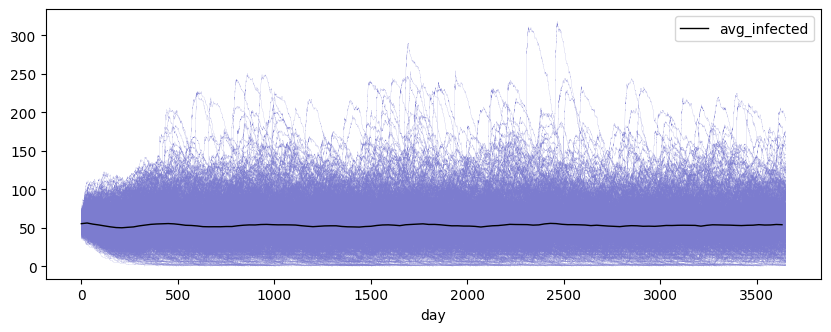

In [39]:
sat3_mean_inf = []
n_day = []

for d in range(0,3650,30):
  n_day = []
  for i in range(0,1000):
    n = reps_sat3[i].asof(d)['infectious'] + reps_sat3[i].asof(d)['carrier']

    if n > 0:
        n_day.append(n)

  n_avg = sum(n_day)/len(n_day)
  day_mean = {'day': d, 'avg_infected': n_avg}
  sat3_mean_inf.append(day_mean)

sat3_mean_inf = pandas.DataFrame(sat3_mean_inf)

fig, ax = plt.subplots(figsize=(10, 3.5))

for i in range(0,1000):
    reps_sat3[i]['total_infected'] = reps_sat3[i]['infectious'] + reps_sat3[i]['carrier']
    reps_sat3[i]['total_infected'].plot(ax=ax, color = '#7c7ccf', alpha = 1, lw = 0.1)

sat3_mean_inf.plot(ax=ax, x = 'day', y = 'avg_infected', color = 'black', lw = 1)

<Axes: xlabel='extinction_year', ylabel='Density'>

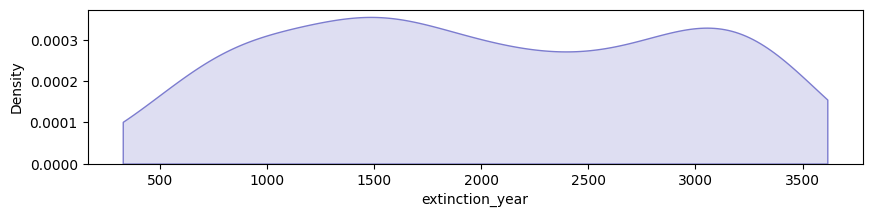

In [40]:

sat3_extinct_true = sat3_extinct.query("extinction == True")

fig, ax = plt.subplots(figsize=(10, 2))

seaborn.kdeplot(data=sat3_extinct_true, x="extinction_year",
                cut = 0, color = '#7c7ccf', fill = True)